# HR Employee Attrition — Week 1: Data Model, Cleaning & Preprocessing
**Dataset:** IBM HR Analytics Employee Attrition (1,470 employees × 35 columns)


**Steps**
1. Load & inspect the raw data
2. Data quality checks (missing values, duplicates, constants, logical consistency, outliers)
3. Cleaning & standardization
4. Feature preparation (labels + bands for analysis)
5. Build the data model (star schema) in SQL
6. Validate with SQL queries
7. Export the cleaned dataset

In [1]:
import pandas as pd, numpy as np, sqlite3, matplotlib.pyplot as plt
pd.set_option('display.max_columns', 50)
RAW = 'data/WA_Fn-UseC_-HR-Employee-Attrition.csv'
df_raw = pd.read_csv(RAW)
df = df_raw.copy()
print('Shape:', df.shape)
df.head()

Shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


## 1. Initial inspection

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0


## 2. Data quality checks

In [4]:
print('Missing values  :', df.isna().sum().sum())
print('Duplicate rows  :', df.duplicated().sum())
print('Duplicate IDs   :', df['EmployeeNumber'].duplicated().sum())
const = [c for c in df.columns if df[c].nunique() == 1]
print('Constant columns:', const)
print('Leading/trailing spaces in text columns:',
      sum((df[c].astype(str) != df[c].astype(str).str.strip()).sum() for c in df.select_dtypes('object')))

Missing values  : 0
Duplicate rows  : 0
Duplicate IDs   : 0
Constant columns: ['EmployeeCount', 'Over18', 'StandardHours']
Leading/trailing spaces in text columns: 0


/tmp/ipykernel_152/2970663829.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  sum((df[c].astype(str) != df[c].astype(str).str.strip()).sum() for c in df.select_dtypes('object')))


In [5]:
# Logical consistency checks (all should be 0)
checks = {
 'Age < 18'                                  : (df.Age < 18).sum(),
 'YearsAtCompany > TotalWorkingYears'        : (df.YearsAtCompany > df.TotalWorkingYears).sum(),
 'YearsInCurrentRole > YearsAtCompany'       : (df.YearsInCurrentRole > df.YearsAtCompany).sum(),
 'YearsWithCurrManager > YearsAtCompany'     : (df.YearsWithCurrManager > df.YearsAtCompany).sum(),
 'YearsSinceLastPromotion > YearsAtCompany'  : (df.YearsSinceLastPromotion > df.YearsAtCompany).sum(),
 'Started working before age 14'             : (df.Age - df.TotalWorkingYears < 14).sum(),
}
pd.Series(checks, name='violations')

Age < 18                                    0
YearsAtCompany > TotalWorkingYears          0
YearsInCurrentRole > YearsAtCompany         0
YearsWithCurrManager > YearsAtCompany       0
YearsSinceLastPromotion > YearsAtCompany    0
Started working before age 14               0
Name: violations, dtype: int64

In [6]:
# Valid range check for ordinal (1-4 / 1-5) columns
ordinal = ['Education','EnvironmentSatisfaction','JobInvolvement','JobSatisfaction','RelationshipSatisfaction',
           'WorkLifeBalance','PerformanceRating','JobLevel','StockOptionLevel']
pd.DataFrame({c: sorted(df[c].unique()) for c in ordinal}.items(), columns=['column','values'])

,column,values
0,Education,"[1, 2, 3, 4, 5]"
1,EnvironmentSatisfaction,"[1, 2, 3, 4]"
2,JobInvolvement,"[1, 2, 3, 4]"
3,JobSatisfaction,"[1, 2, 3, 4]"
4,RelationshipSatisfaction,"[1, 2, 3, 4]"
5,WorkLifeBalance,"[1, 2, 3, 4]"
6,PerformanceRating,"[3, 4]"
7,JobLevel,"[1, 2, 3, 4, 5]"
8,StockOptionLevel,"[0, 1, 2, 3]"


In [7]:
# Outlier detection (IQR rule) - for reporting only
num = ['Age','MonthlyIncome','TotalWorkingYears','YearsAtCompany','YearsInCurrentRole',
       'YearsSinceLastPromotion','YearsWithCurrManager','NumCompaniesWorked','TrainingTimesLastYear','DistanceFromHome']
rows=[]
for c in num:
    q1,q3 = df[c].quantile([.25,.75]); iqr=q3-q1
    n = ((df[c] < q1-1.5*iqr) | (df[c] > q3+1.5*iqr)).sum()
    rows.append((c, n, round(100*n/len(df),1)))
pd.DataFrame(rows, columns=['column','outliers','pct'])

,column,outliers,pct
0,Age,0,0.0
1,MonthlyIncome,114,7.8
2,TotalWorkingYears,63,4.3
3,YearsAtCompany,104,7.1
4,YearsInCurrentRole,21,1.4
5,YearsSinceLastPromotion,107,7.3
6,YearsWithCurrManager,14,1.0
7,NumCompaniesWorked,52,3.5
8,TrainingTimesLastYear,238,16.2
9,DistanceFromHome,0,0.0


/tmp/ipykernel_152/304924882.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[c], vert=False); ax.set_title(c)
/tmp/ipykernel_152/304924882.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[c], vert=False); ax.set_title(c)
/tmp/ipykernel_152/304924882.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[c], vert=False); ax.set_title(c)
/tmp/ipykernel_152/304924882.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[c], vert=False); ax.set_title(c)
/tmp/ipykernel_152/304924882.py:3: M

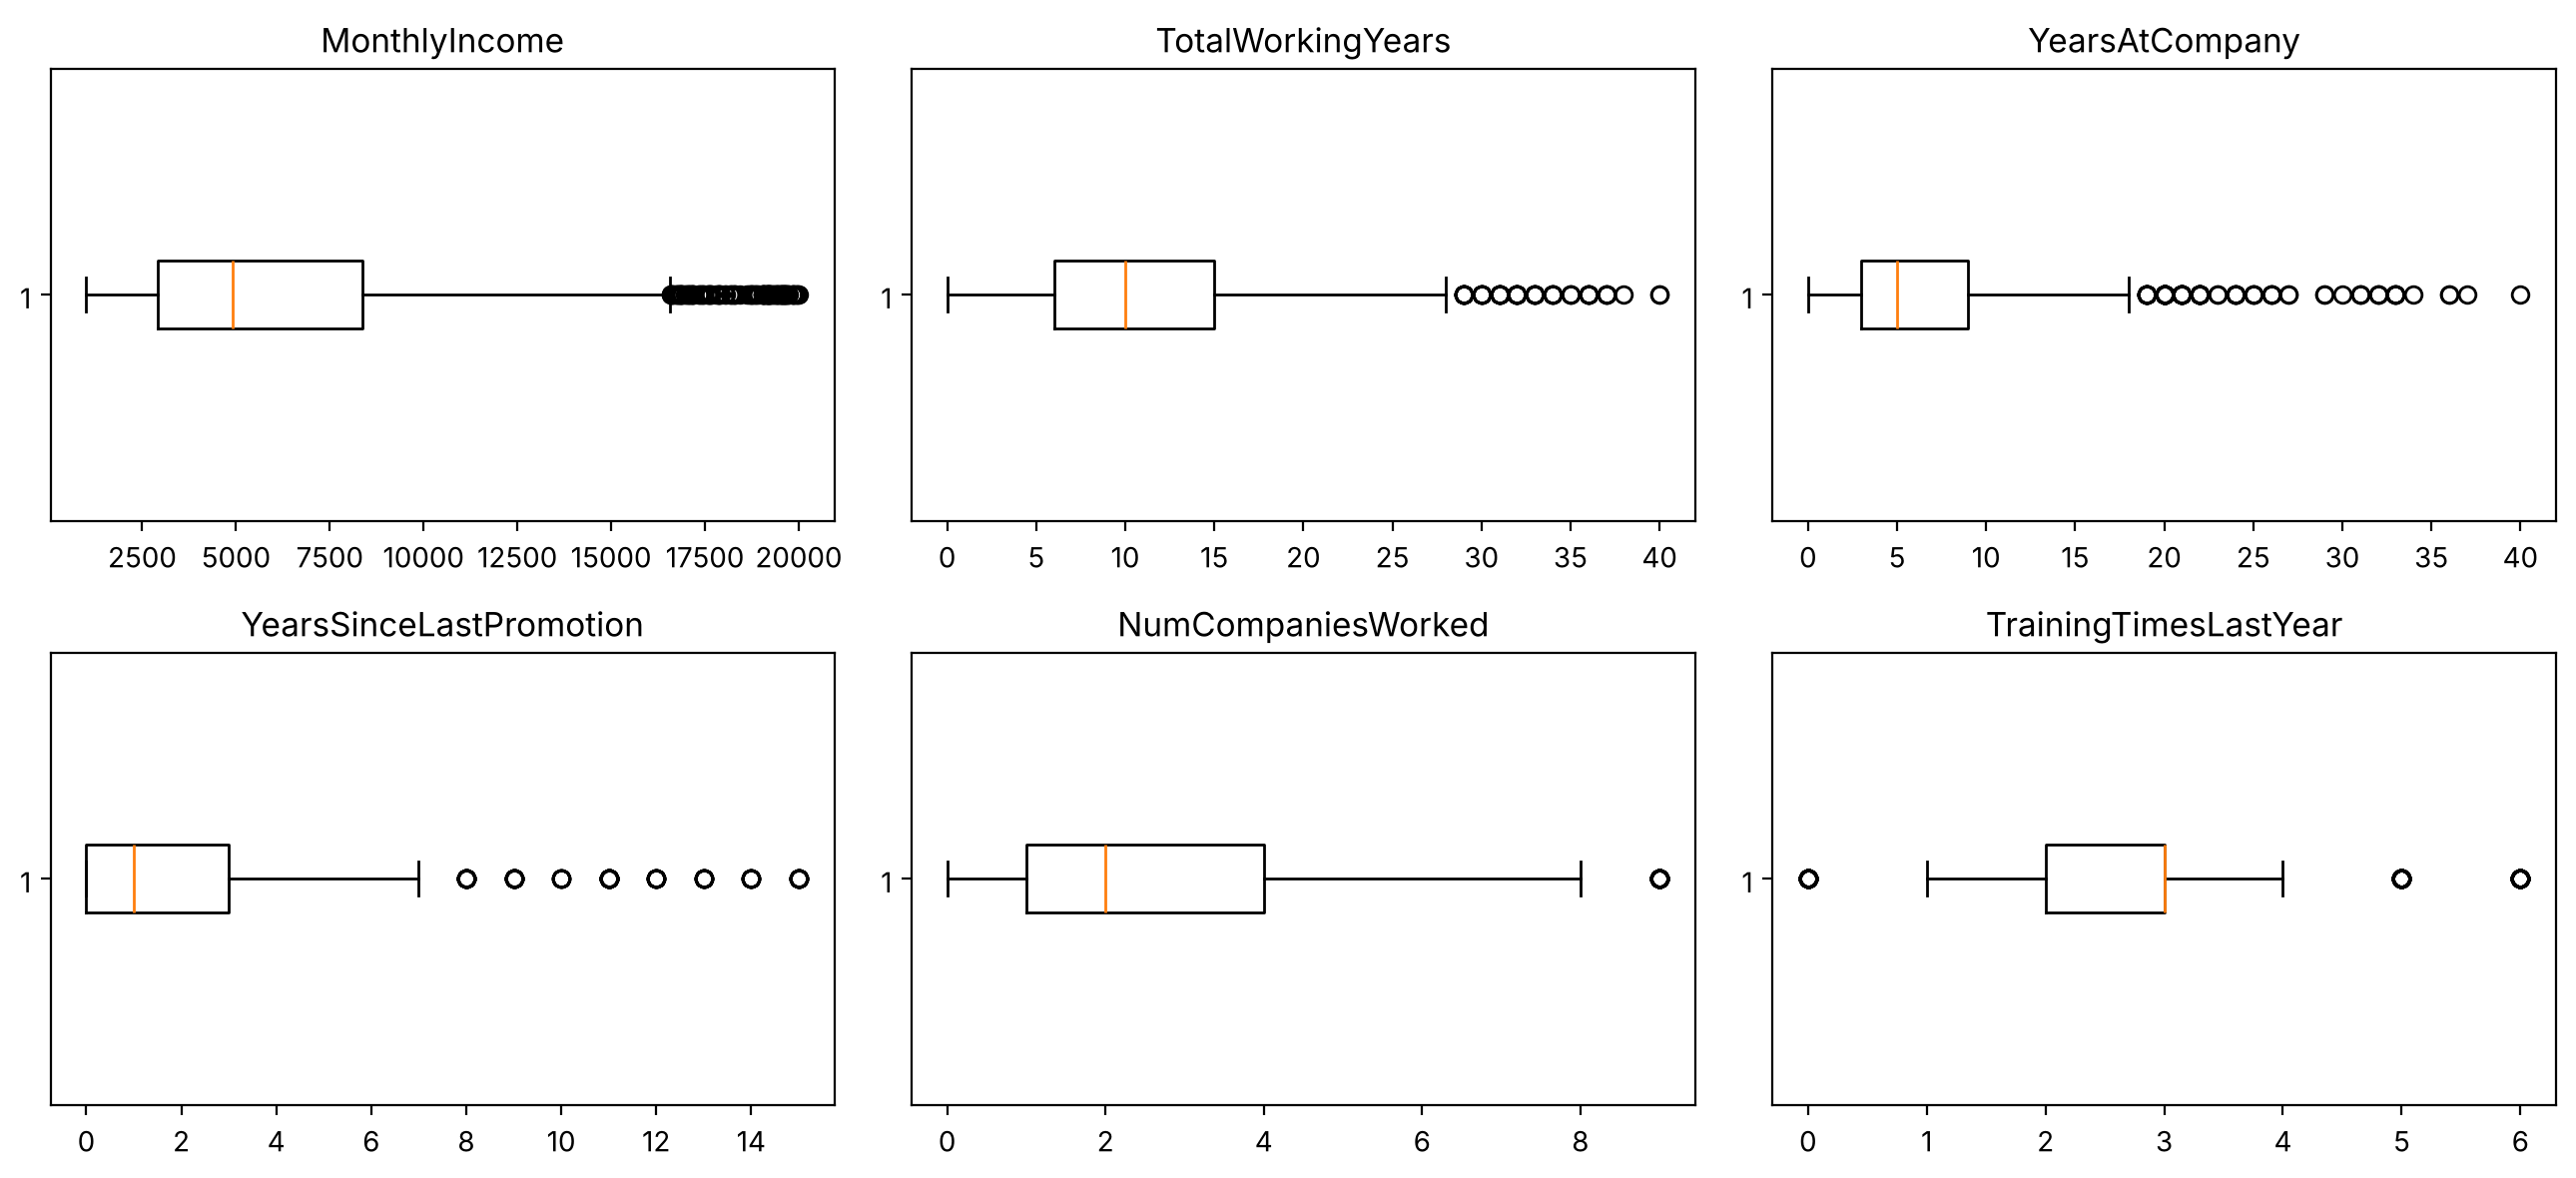

In [8]:
fig, axes = plt.subplots(2,3, figsize=(13,6))
for ax,c in zip(axes.ravel(), ['MonthlyIncome','TotalWorkingYears','YearsAtCompany','YearsSinceLastPromotion','NumCompaniesWorked','TrainingTimesLastYear']):
    ax.boxplot(df[c], vert=False); ax.set_title(c)
plt.tight_layout(); plt.savefig('figures/outliers_boxplots.png', dpi=130); plt.show()

**Findings**
- No missing values, no duplicate rows, `EmployeeNumber` is unique.
- 3 constant columns (`EmployeeCount`, `Over18`, `StandardHours`) carry no information → dropped.
- All logical-consistency checks pass.
- IQR outliers exist (income, years at company, years since promotion…) but they are **realistic values** (senior staff, long tenure), not errors → **kept**.

## 3. Cleaning & standardization

In [9]:
# 3.1 Drop constant columns
df = df.drop(columns=['EmployeeCount','Over18','StandardHours'])

# 3.2 snake_case column names
import re
def snake(s):
    s = re.sub(r'(?<=[a-z0-9])(?=[A-Z])', '_', s)
    return s.lower()
df.columns = [snake(c) for c in df.columns]
df = df.rename(columns={'employee_number':'employee_id'})

# 3.3 Clean text values
for c in df.select_dtypes('object'):
    df[c] = df[c].str.strip()
df['business_travel'] = df['business_travel'].str.replace('_',' ')

# 3.4 Binary flags for Yes/No columns (original text kept)
df['attrition_flag'] = (df['attrition']=='Yes').astype(int)
df['overtime_flag']  = (df['over_time']=='Yes').astype(int)
df = df.rename(columns={'over_time':'overtime'})

# 3.5 Data types
cat_cols = ['attrition','business_travel','department','education_field','gender','job_role','marital_status','overtime']
df[cat_cols] = df[cat_cols].astype('category')
df = df.sort_values('employee_id').reset_index(drop=True)
print(df.shape); df.dtypes

(1470, 34)


/tmp/ipykernel_152/1485345396.py:13: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for c in df.select_dtypes('object'):


age                              int64
attrition                     category
business_travel               category
daily_rate                       int64
department                    category
distance_from_home               int64
education                        int64
education_field               category
employee_id                      int64
environment_satisfaction         int64
gender                        category
hourly_rate                      int64
job_involvement                  int64
job_level                        int64
job_role                      category
job_satisfaction                 int64
marital_status                category
monthly_income                   int64
monthly_rate                     int64
num_companies_worked             int64
overtime                      category
percent_salary_hike              int64
performance_rating               int64
relationship_satisfaction        int64
stock_option_level               int64
total_working_years      

## 4. Feature preparation

In [10]:
# Human-readable labels for coded columns (per the dataset documentation)
edu   = {1:'Below College',2:'College',3:'Bachelor',4:'Master',5:'Doctor'}
sat   = {1:'Low',2:'Medium',3:'High',4:'Very High'}
perf  = {1:'Low',2:'Good',3:'Excellent',4:'Outstanding'}
wlb   = {1:'Bad',2:'Good',3:'Better',4:'Best'}

df['education_label']                = df['education'].map(edu)
df['job_satisfaction_label']         = df['job_satisfaction'].map(sat)
df['environment_satisfaction_label'] = df['environment_satisfaction'].map(sat)
df['relationship_satisfaction_label']= df['relationship_satisfaction'].map(sat)
df['job_involvement_label']          = df['job_involvement'].map(sat)
df['performance_rating_label']       = df['performance_rating'].map(perf)
df['work_life_balance_label']        = df['work_life_balance'].map(wlb)

# Bands for grouping in analysis / dashboards
df['age_group'] = pd.cut(df['age'], [17,25,35,45,55,100], labels=['18-25','26-35','36-45','46-55','56+'])
df['income_band'] = pd.cut(df['monthly_income'], [0,3000,6000,10000,20000], labels=['<3K','3K-6K','6K-10K','10K+'])
df['tenure_band'] = pd.cut(df['years_at_company'], [-1,2,5,10,50], labels=['0-2','3-5','6-10','10+'])
df['distance_band'] = pd.cut(df['distance_from_home'], [0,5,10,20,100], labels=['1-5','6-10','11-20','20+'])
df[['age','age_group','monthly_income','income_band','years_at_company','tenure_band']].head()

,age,age_group,monthly_income,income_band,years_at_company,tenure_band
0,41,36-45,5993,3K-6K,6,6-10
1,49,46-55,5130,3K-6K,10,6-10
2,37,36-45,2090,<3K,0,0-2
3,33,26-35,2909,<3K,8,6-10
4,27,26-35,3468,3K-6K,2,0-2


## 5. Data model (star schema in SQL)

The flat file mixes employee attributes, organisational attributes and measures. It is split into:

| Table | Type | Content |
|---|---|---|
| `dim_employee` | Dimension | age, age group, gender, marital status, education, distance from home |
| `dim_department` | Dimension | department |
| `dim_job_role` | Dimension | job role |
| `dim_education_field` | Dimension | field of education |
| `fact_employment` | Fact | one row per employee: FKs + attrition, pay, tenure, satisfaction & performance measures |

(`JobRole` is separate from `Department` because the *Manager* role appears in 3 departments.)

In [11]:
schema = '''
DROP TABLE IF EXISTS fact_employment;
DROP TABLE IF EXISTS dim_employee;
DROP TABLE IF EXISTS dim_department;
DROP TABLE IF EXISTS dim_job_role;
DROP TABLE IF EXISTS dim_education_field;

CREATE TABLE dim_department (
    department_id INTEGER PRIMARY KEY,
    department    TEXT NOT NULL UNIQUE
);
CREATE TABLE dim_job_role (
    job_role_id INTEGER PRIMARY KEY,
    job_role    TEXT NOT NULL UNIQUE
);
CREATE TABLE dim_education_field (
    education_field_id INTEGER PRIMARY KEY,
    education_field    TEXT NOT NULL UNIQUE
);
CREATE TABLE dim_employee (
    employee_id        INTEGER PRIMARY KEY,
    age                INTEGER NOT NULL CHECK (age >= 18),
    age_group          TEXT,
    gender             TEXT,
    marital_status     TEXT,
    education          INTEGER CHECK (education BETWEEN 1 AND 5),
    education_label    TEXT,
    education_field_id INTEGER REFERENCES dim_education_field(education_field_id),
    distance_from_home INTEGER,
    distance_band      TEXT
);
CREATE TABLE fact_employment (
    employee_id                 INTEGER PRIMARY KEY REFERENCES dim_employee(employee_id),
    department_id               INTEGER NOT NULL REFERENCES dim_department(department_id),
    job_role_id                 INTEGER NOT NULL REFERENCES dim_job_role(job_role_id),
    job_level                   INTEGER,
    business_travel             TEXT,
    overtime                    TEXT,
    overtime_flag               INTEGER,
    attrition                   TEXT,
    attrition_flag              INTEGER,
    monthly_income              INTEGER,
    income_band                 TEXT,
    daily_rate                  INTEGER,
    hourly_rate                 INTEGER,
    monthly_rate                INTEGER,
    percent_salary_hike         INTEGER,
    stock_option_level          INTEGER,
    total_working_years         INTEGER,
    num_companies_worked        INTEGER,
    years_at_company            INTEGER,
    tenure_band                 TEXT,
    years_in_current_role       INTEGER,
    years_since_last_promotion  INTEGER,
    years_with_curr_manager     INTEGER,
    training_times_last_year    INTEGER,
    job_satisfaction            INTEGER,
    environment_satisfaction    INTEGER,
    relationship_satisfaction   INTEGER,
    job_involvement             INTEGER,
    work_life_balance           INTEGER,
    performance_rating          INTEGER
);
CREATE INDEX idx_fact_dept ON fact_employment(department_id);
CREATE INDEX idx_fact_role ON fact_employment(job_role_id);
'''
open('schema.sql','w').write(schema)

con = sqlite3.connect('hr_attrition.db')
con.executescript(schema)

def dim(col, table, idcol):
    d = pd.DataFrame({col: sorted(df[col].astype(str).unique())}); d.insert(0, idcol, range(1,len(d)+1))
    d.to_sql(table, con, if_exists='append', index=False); return d
d_dep  = dim('department','dim_department','department_id')
d_role = dim('job_role','dim_job_role','job_role_id')
d_edf  = dim('education_field','dim_education_field','education_field_id')

m = df.copy()
for c in ['department','job_role','education_field','age_group','income_band','tenure_band','distance_band']:
    m[c] = m[c].astype(str)
m = (m.merge(d_dep,on='department').merge(d_role,on='job_role').merge(d_edf,on='education_field'))

emp_cols = ['employee_id','age','age_group','gender','marital_status','education','education_label','education_field_id','distance_from_home','distance_band']
fact_cols = ['employee_id','department_id','job_role_id','job_level','business_travel','overtime','overtime_flag','attrition','attrition_flag',
 'monthly_income','income_band','daily_rate','hourly_rate','monthly_rate','percent_salary_hike','stock_option_level','total_working_years',
 'num_companies_worked','years_at_company','tenure_band','years_in_current_role','years_since_last_promotion','years_with_curr_manager',
 'training_times_last_year','job_satisfaction','environment_satisfaction','relationship_satisfaction','job_involvement','work_life_balance','performance_rating']
con.execute('PRAGMA foreign_keys = ON')
m[emp_cols].to_sql('dim_employee', con, if_exists='append', index=False)
m[fact_cols].to_sql('fact_employment', con, if_exists='append', index=False)
con.commit()
pd.read_sql("SELECT name, (SELECT COUNT(*) FROM pragma_table_info(name)) AS columns FROM sqlite_master WHERE type='table'", con)

,name,columns
0,dim_department,0
1,dim_job_role,0
2,dim_education_field,0
3,dim_employee,0
4,fact_employment,0


## 6. SQL validation

In [12]:
q = lambda s: pd.read_sql(s, con)
print(q('''SELECT (SELECT COUNT(*) FROM dim_employee) AS employees,
                  (SELECT COUNT(*) FROM fact_employment) AS facts,
                  (SELECT COUNT(*) FROM fact_employment f LEFT JOIN dim_employee e USING(employee_id) WHERE e.employee_id IS NULL) AS orphan_facts''').to_string(index=False))
print(q('PRAGMA foreign_key_check').shape[0], 'foreign-key violations')
q('''SELECT d.department, COUNT(*) AS employees, ROUND(100.0*AVG(f.attrition_flag),1) AS attrition_pct,
            ROUND(AVG(f.monthly_income)) AS avg_income
     FROM fact_employment f JOIN dim_department d USING(department_id)
     GROUP BY d.department ORDER BY employees DESC''')

 employees  facts  orphan_facts
      1470   1470             0
0 foreign-key violations


,department,employees,attrition_pct,avg_income
0,Research & Development,961,13.8,6281.0
1,Sales,446,20.6,6959.0
2,Human Resources,63,19.0,6655.0


Attrition count matches: 237 | rate = 16.1 %


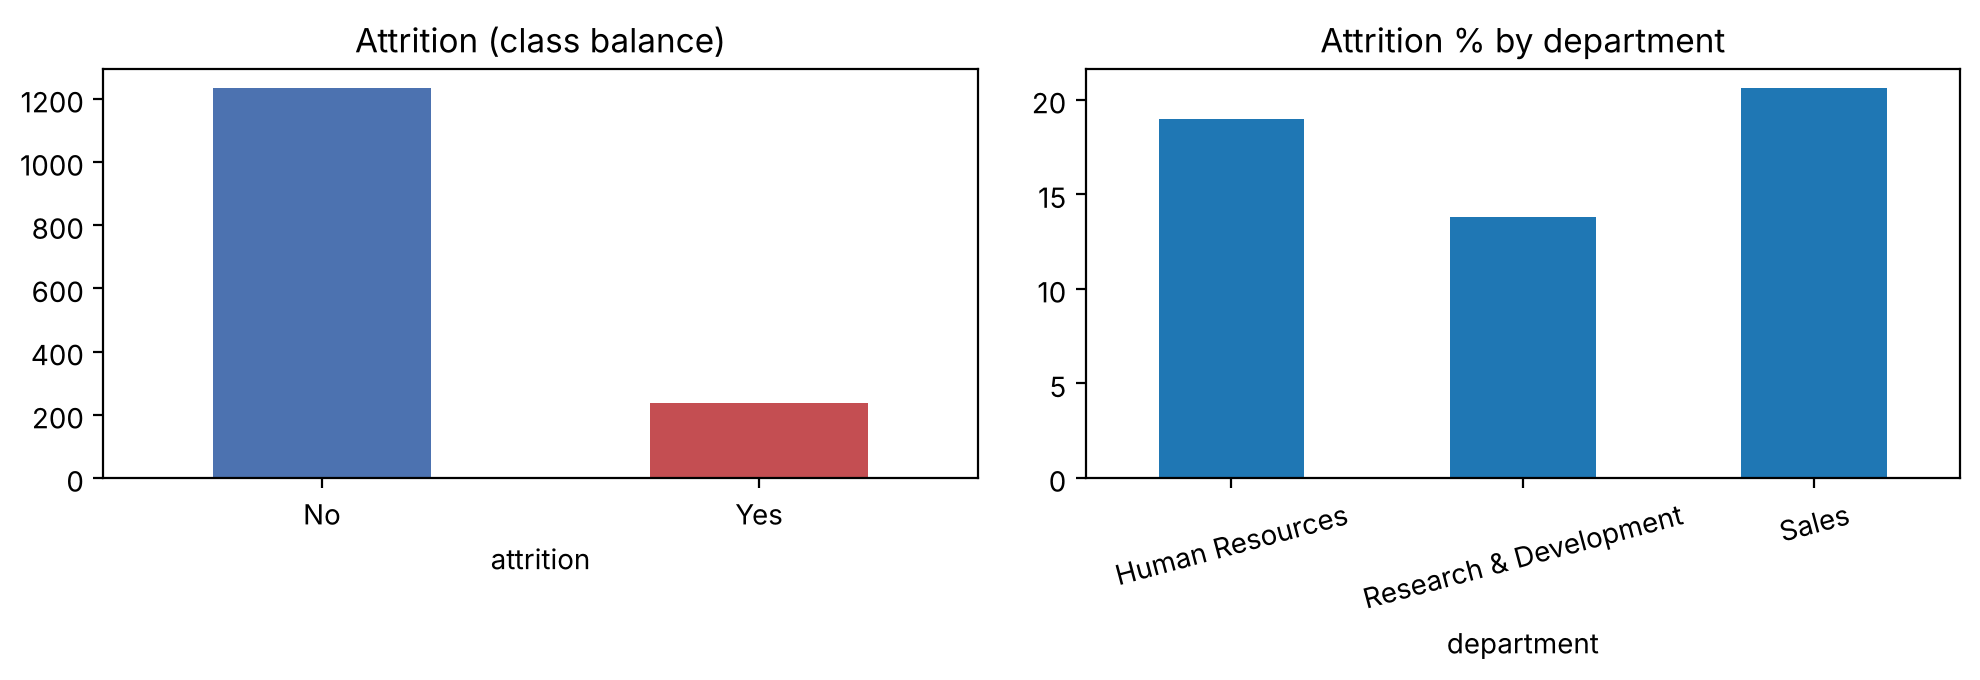

In [13]:
# Joined view sanity check: SQL result must equal the pandas result
sql_attr = q('SELECT SUM(attrition_flag) AS n FROM fact_employment').iloc[0,0]
assert sql_attr == df['attrition_flag'].sum()
print('Attrition count matches:', sql_attr, '| rate =', round(100*sql_attr/len(df),1), '%')
fig, ax = plt.subplots(1,2, figsize=(10,3.5))
df['attrition'].value_counts().plot.bar(ax=ax[0], color=['#4c72b0','#c44e52'], rot=0, title='Attrition (class balance)')
df.groupby('department', observed=True)['attrition_flag'].mean().mul(100).round(1).plot.bar(ax=ax[1], rot=15, title='Attrition % by department')
plt.tight_layout(); plt.savefig('figures/attrition_overview.png', dpi=130); plt.show()

## 7. Export the cleaned dataset

In [14]:
df.to_csv('data/hr_attrition_cleaned.csv', index=False)
chk = pd.read_csv('data/hr_attrition_cleaned.csv')
print('Cleaned file:', chk.shape, '| missing =', chk.isna().sum().sum())
print('Columns removed :', sorted(set(snake(c) for c in df_raw.columns) - set(chk.columns) - {'employee_number','over_time'}))
print('Columns added   :', [c for c in chk.columns if c not in [snake(x) for x in df_raw.columns] + ['employee_id','overtime']])
con.close()

Cleaned file: (1470, 45) | missing = 0
Columns removed : ['employee_count', 'over18', 'standard_hours']
Columns added   : ['attrition_flag', 'overtime_flag', 'education_label', 'job_satisfaction_label', 'environment_satisfaction_label', 'relationship_satisfaction_label', 'job_involvement_label', 'performance_rating_label', 'work_life_balance_label', 'age_group', 'income_band', 'tenure_band', 'distance_band']


## Summary
| | Raw | Cleaned |
|---|---|---|
| Rows | 1,470 | 1,470 |
| Columns | 35 | 45 (3 constant dropped, 13 derived added) |
| Missing / duplicates | 0 / 0 | 0 / 0 |

